使用pytorch构建mlp模型

In [79]:
import time
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score
from torch.utils.data import DataLoader, TensorDataset

class MLP(nn.Module):
    def __init__(self, input_size, hidden_size=64, output_size=1):
        super(MLP, self).__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(hidden_size, output_size)
        self.sigmoid = nn.Sigmoid()
        
    def forward(self, x):
        out = self.fc1(x)
        out = self.relu(out)
        out = self.fc2(out)
        out = self.sigmoid(out)
        return out

加载数据

In [80]:
def load_data(X_path, y_path):
    """加载数据并转换为PyTorch张量"""
    X = pd.read_csv(X_path)
    y = pd.read_csv(y_path)
    
    assert len(X) == len(y), "X和y的行数不匹配"
    
    X_tensor = torch.FloatTensor(X.values)
    y_tensor = torch.FloatTensor(y.values)
    
    return X_tensor, y_tensor

可视化结果

In [81]:
def plot_learning_curves(train_loss, train_acc, test_loss=None, test_acc=None, 
                        plot_interval=1, title="Learning Curves"):
    """绘制学习曲线（可控制绘图间隔）
    
    Args:
        plot_interval: 每隔多少代绘制一个点（默认每代都绘制）
    """
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
    
    # 创建索引数组（考虑间隔）
    epochs = range(len(train_loss))
    plot_indices = epochs[::plot_interval]
    if epochs[-1] not in plot_indices:  # 确保包含最后一个点
        plot_indices = list(plot_indices) + [epochs[-1]]
    
    # 绘制损失曲线（带间隔）
    ax1.plot(plot_indices, [train_loss[i] for i in plot_indices], 
             'o-', label='Train Loss', color='tab:blue', markersize=5)
    if test_loss is not None:
        ax1.plot(plot_indices, [test_loss[i] for i in plot_indices], 
                 'o-', label='Test Loss', color='tab:red', markersize=5)
    
    # 设置x轴刻度
    ax1.set_xticks(plot_indices)
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Loss')
    ax1.set_title('Training & Test Loss')
    ax1.legend()
    ax1.grid(True)
    
    # 绘制准确率曲线（带间隔）
    ax2.plot(plot_indices, [train_acc[i] for i in plot_indices], 
             'o-', label='Train Accuracy', color='tab:orange', markersize=5)
    if test_acc is not None:
        ax2.plot(plot_indices, [test_acc[i] for i in plot_indices], 
                 'o-', label='Test Accuracy', color='tab:green', markersize=5)
    
    # 设置x轴刻度（与损失图一致）
    ax2.set_xticks(plot_indices)
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Accuracy')
    ax2.set_title('Training & Test Accuracy')
    ax2.legend()
    ax2.grid(True)
    
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

训练模型

In [82]:
def train_model(model, train_loader, criterion, optimizer, device, test_loader=None, epochs=100):
    """训练模型并记录损失和准确率"""
    train_loss_history = []
    train_acc_history = []
    test_loss_history = []
    test_acc_history = []
    
    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0
        
        # 训练阶段
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            
            # 前向传播
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            
            # 反向传播和优化
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            
            # 统计信息
            running_loss += loss.item()
            predicted = (outputs > 0.5).float()
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
        
        # 计算训练集指标
        train_loss = running_loss / len(train_loader)
        train_acc = correct / total
        train_loss_history.append(train_loss)
        train_acc_history.append(train_acc)
        
        # 测试阶段
        if test_loader is not None:
            test_loss, test_acc = evaluate_model(model, test_loader, criterion, device)
            test_loss_history.append(test_loss)
            test_acc_history.append(test_acc)
        
        # 打印进度
        if (epoch+1) % 10 == 0:
            print(f'Epoch [{epoch+1}/{epochs}], Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f}', end='')
            if test_loader is not None:
                print(f', Test Loss: {test_loss:.4f}, Test Acc: {test_acc:.4f}')
            else:
                print()
    
    return train_loss_history, train_acc_history, test_loss_history, test_acc_history

评估模型

In [83]:
def evaluate_model(model, data_loader, criterion, device):
    """评估模型性能"""
    model.eval()
    correct = 0
    total = 0
    running_loss = 0.0
    
    with torch.no_grad():
        for inputs, labels in data_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            
            running_loss += loss.item()
            predicted = (outputs > 0.5).float()
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    
    avg_loss = running_loss / len(data_loader)
    accuracy = correct / total
    
    return avg_loss, accuracy

进行训练和预测

Starting Training...
Epoch [10/300], Train Loss: 0.9441, Train Acc: 0.4605, Test Loss: 0.9550, Test Acc: 0.3704
Epoch [20/300], Train Loss: 0.4610, Train Acc: 0.8974, Test Loss: 0.3965, Test Acc: 0.8730
Epoch [30/300], Train Loss: 0.3782, Train Acc: 0.9026, Test Loss: 0.3366, Test Acc: 0.8889
Epoch [40/300], Train Loss: 0.3117, Train Acc: 0.9079, Test Loss: 0.2964, Test Acc: 0.9101
Epoch [50/300], Train Loss: 0.2704, Train Acc: 0.9132, Test Loss: 0.2708, Test Acc: 0.9153
Epoch [60/300], Train Loss: 0.2433, Train Acc: 0.9184, Test Loss: 0.2752, Test Acc: 0.9048
Epoch [70/300], Train Loss: 0.2159, Train Acc: 0.9184, Test Loss: 0.2503, Test Acc: 0.9101
Epoch [80/300], Train Loss: 0.2099, Train Acc: 0.9158, Test Loss: 0.2398, Test Acc: 0.9206
Epoch [90/300], Train Loss: 0.2074, Train Acc: 0.9184, Test Loss: 0.2407, Test Acc: 0.9153
Epoch [100/300], Train Loss: 0.2008, Train Acc: 0.9158, Test Loss: 0.2542, Test Acc: 0.9153
Epoch [110/300], Train Loss: 0.1979, Train Acc: 0.9132, Test Loss: 0

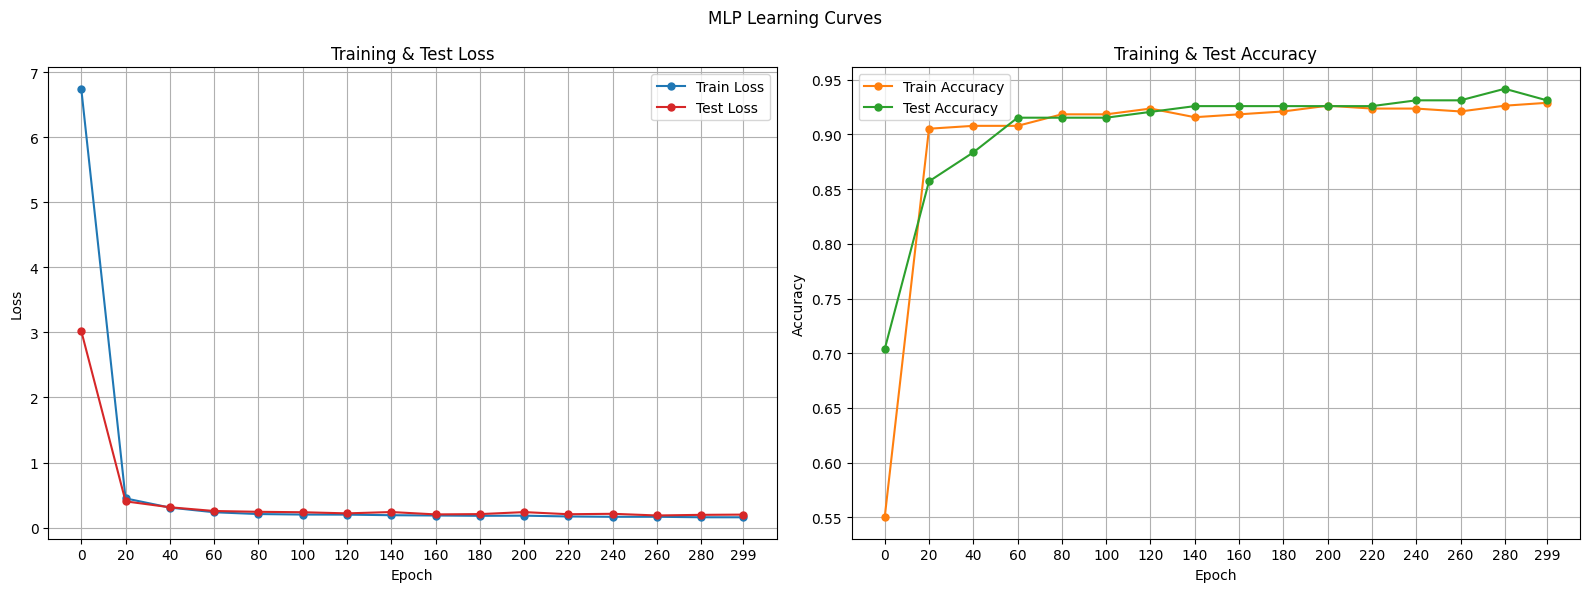


Final Results:
Training Loss: 0.1548, Training Accuracy: 0.9342
Test Loss: 0.2004, Test Accuracy: 0.9312


In [84]:
def main():
    
    # 设置随机种子保证可重复性
    torch.manual_seed(42)
    
    # 加载数据
    x_train, y_train = load_data('data/train/X_train.csv', 'data/train/Y_train.csv')
    x_test, y_test = load_data('data/test/X_test.csv', 'data/test/Y_test.csv')
    
    # 创建数据集和数据加载器
    train_dataset = TensorDataset(x_train, y_train)
    test_dataset = TensorDataset(x_test, y_test)
    
    batch_size = 32
    train_loader = DataLoader(dataset=train_dataset, batch_size=batch_size, shuffle=True)
    test_loader = DataLoader(dataset=test_dataset, batch_size=batch_size, shuffle=False)
    
    # 检查GPU可用性
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    
    # 初始化模型
    input_size = x_train.shape[1]
    model = MLP(input_size).to(device)
    
    # 定义损失函数和优化器
    criterion = nn.BCELoss()
    optimizer = optim.Adam(model.parameters(), lr=0.0001)
    
    # 训练模型
    print("Starting Training...")
    start=time.time()
    train_loss, train_acc, test_loss, test_acc = train_model(
        model, train_loader, criterion, optimizer, device, test_loader, epochs=300
    )
    end=time.time()
    print("Training Time: {:.2f} seconds".format(end-start))
    
    # 绘制学习曲线
    plot_learning_curves(train_loss, train_acc, test_loss, test_acc,
                         plot_interval=20,title="MLP Learning Curves")
    
    # 最终评估
    final_train_loss, final_train_acc = evaluate_model(model, train_loader, criterion, device)
    final_test_loss, final_test_acc = evaluate_model(model, test_loader, criterion, device)
    
    print("\nFinal Results:")
    print(f"Training Loss: {final_train_loss:.4f}, Training Accuracy: {final_train_acc:.4f}")
    print(f"Test Loss: {final_test_loss:.4f}, Test Accuracy: {final_test_acc:.4f}")

if __name__ == "__main__":
    main()